In [1]:
import numpy as np 
import pandas as pd
from modules import SumoSimulation,update_green_times,create_initial_tl_df,ErrorFunction,InitialSamples,SumoSimulation,get_upper_bounds,BOLoop,RAASP_sampler,TRCandidatesGeneration,TrustRegionInitialization,TurboLoop
import sumolib
from lxml import etree
import torch
import sympy as sp
from torch.quasirandom import SobolEngine
import matplotlib.pyplot as plt


c:\Users\sh032\anaconda3\envs\thesis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
# Creation of the Ground Truth Dataframe
net=sumolib.net.readNet("Ingolstadt Network/ingolstadt.net.xml")
tl_ids=[tl.getID() for tl in net.getTrafficLights()]
num_replications=5
cfg_file="Ingolstadt Network/InTAS_gt.sumocfg"
output_dir="gt_data/"

gt_sumo_simulator=SumoSimulation(num_replications,cfg_file,output_dir,tl_ids)

In [ ]:
# Creation of the Ground Truth Dataframe
epoch_index="gt"

gt_sumo_simulator.simulation(epoch_index)

In [8]:
df_gt=pd.read_csv("./gt_data/gt_InTAS.travel_times.csv")
net=sumolib.net.readNet("Ingolstadt Network/ingolstadt.net.xml")
tl_ids=[tl.getID() for tl in net.getTrafficLights()]

additional_xml_gt="./Ingolstadt Network/additional_gt.xml"
initial_tl_df=create_initial_tl_df(additional_xml_gt)
num_replications=5
cfg_file="./Ingolstadt Network/InTAS.sumocfg"
output_dir="initial_output/"
additional_xml="./Ingolstadt Network/additional.xml"
dtype=torch.double

init_sumo_simulator=SumoSimulation(num_replications=num_replications,
                                   cfg_file=cfg_file,
                                   output_dir=output_dir,
                                   tl_ids=tl_ids,
                                   )

init_objective_function=ErrorFunction(
    initial_tl_df=initial_tl_df,
    output_dir=output_dir,
    sumo_simulator=init_sumo_simulator,
    df_gt=df_gt,
    additional_xml=additional_xml,
    tl_ids=tl_ids
)

initial_sampler=InitialSamples(dtype=dtype,
                               objective_function=init_objective_function,
                               initial_tl_df=initial_tl_df)

In [ ]:
sample_size=5
x_dim=98
lower_bounds=[5]*x_dim
upper_bounds=get_upper_bounds(initial_tl_df)
x_bounds=torch.tensor(
    [lower_bounds,
    upper_bounds],
    dtype=dtype
)
n_restart=5

init_X_norm_list=[]
init_Y_list=[]
init_df_list=[]

for i in range(n_restart):
    init_X_norm, init_Y, init_df=initial_sampler.get_initial_sample(sample_size,x_dim,x_bounds)
    init_X_norm_list.append(init_X_norm)
    init_Y_list.append(init_Y)
    init_df_list.append(init_df)

torch.save(init_X_norm_list,"./initial_samples/init_X_norm.pt")
torch.save(init_Y_list,"./initial_samples/init_Y.pt")
torch.save(init_df_list,"./initial_samples/init_df.pt")

In [ ]:
pow(10,-3)

In [2]:
niter=10
num_restart=5
init_df_list=torch.load("./initial_samples/init_df.pt",weights_only=False)
output_dir="BO_output/"
dtype=torch.double
x_dim=98
lower_bounds=[5]*x_dim
additional_xml_gt="./Ingolstadt Network/additional_gt.xml"
initial_tl_df=create_initial_tl_df(additional_xml_gt)
upper_bounds=get_upper_bounds(initial_tl_df)
bounds=torch.tensor(
    [lower_bounds,
    upper_bounds],
    dtype=dtype
)


df_gt=pd.read_csv("./gt_data/gt_InTAS.travel_times.csv")
net=sumolib.net.readNet("Ingolstadt Network/ingolstadt.net.xml")
tl_ids=[tl.getID() for tl in net.getTrafficLights()]
num_replications=5
cfg_file="./Ingolstadt Network/InTAS.sumocfg"
additional_xml="./Ingolstadt Network/additional.xml"

raw_samples=128
batch_size=1
num_restarts_opti=5
device=(torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu"))


sumo_simulator=SumoSimulation(num_replications=num_replications,
                                   cfg_file=cfg_file,
                                   output_dir=output_dir,
                                   tl_ids=tl_ids,
                                   )

objective_function=ErrorFunction(
    initial_tl_df=initial_tl_df,
    output_dir=output_dir,
    sumo_simulator=sumo_simulator,
    df_gt=df_gt,
    additional_xml=additional_xml,
    tl_ids=tl_ids
)

BO_instance=BOLoop(niter=niter,
                   num_restart=num_restart,
                   init_df_list=init_df_list,
                   output_dir=output_dir,
                   bounds=bounds,
                   objective_function=objective_function,
                   dtype=dtype,
                   x_dim=x_dim,
                   device=device,
                   num_restarts_opti=num_restarts_opti,
                   raw_samples=raw_samples,
                   batch_size=batch_size,
                   initial_tl_df=initial_tl_df)

In [ ]:
BO_instance.run_loop(version="VANILLA",initial_length_scale_value=0.1)

In [4]:
best_df_all=None
for rs in range(num_restart):
    restart_output=pd.read_csv(f'{output_dir}BO_df_VANILLA_restart{rs}.csv')
    restart_output["best_loss"]=restart_output.groupby("iter")["loss_estimate"].transform(lambda x : restart_output.loc[restart_output["iter"]<=x.name,"loss_estimate"].min())
    if best_df_all is None:
        best_df_all=restart_output
    else:
        best_df_all=pd.concat([best_df_all,restart_output],axis=0)

best_df_all=best_df_all.groupby("iter")["loss_estimate"].agg(["mean","std"]).reset_index().rename(columns={"mean":"best_loss_mean","std":"best_loss_std"})

C:\Users\sh032\AppData\Local\Temp\ipykernel_33908\3438197759.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  restart_output["best_loss"]=restart_output.groupby("iter")["loss_estimate"].transform(lambda x : restart_output.loc[restart_output["iter"]<=x.name,"loss_estimate"].min())


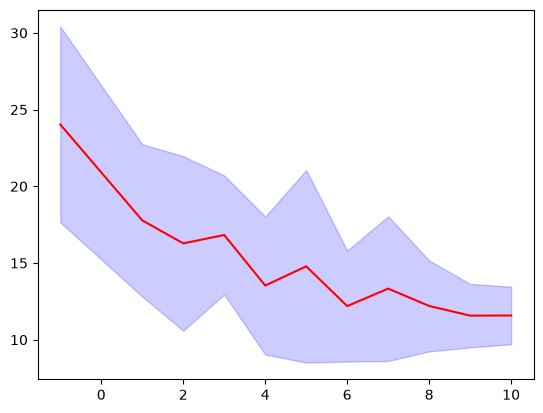

In [5]:
plt.figure()
plt.plot(best_df_all.iter, best_df_all.best_loss_mean,color="red")
plt.fill_between(best_df_all.iter, 
                 best_df_all.best_loss_mean - best_df_all.best_loss_std, 
                 best_df_all.best_loss_mean + best_df_all.best_loss_std, 
                 alpha=0.2, color = 'blue')

In [6]:
test=torch.tensor([1,2])
val,ind=torch.max(test,dim=0)
print(val.item())
print(ind.item())

2
1


# MSR Version

In [2]:
niter=10
num_restart=5
init_df_list=torch.load("./initial_samples/init_df.pt",weights_only=False)
output_dir="BO_output/"
dtype=torch.double
x_dim=98
lower_bounds=[5]*x_dim
additional_xml_gt="./Ingolstadt Network/additional_gt.xml"
initial_tl_df=create_initial_tl_df(additional_xml_gt)
upper_bounds=get_upper_bounds(initial_tl_df)
bounds=torch.tensor(
    [lower_bounds,
    upper_bounds],
    dtype=dtype
)


df_gt=pd.read_csv("./gt_data/gt_InTAS.travel_times.csv")
net=sumolib.net.readNet("Ingolstadt Network/ingolstadt.net.xml")
tl_ids=[tl.getID() for tl in net.getTrafficLights()]
num_replications=5
cfg_file="./Ingolstadt Network/InTAS.sumocfg"
additional_xml="./Ingolstadt Network/additional.xml"

raw_samples=512
batch_size=1
num_restarts_opti=5
device=(torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu"))

RAASP_sampler=RAASP_sampler(x_dim)

sumo_simulator=SumoSimulation(num_replications=num_replications,
                                   cfg_file=cfg_file,
                                   output_dir=output_dir,
                                   tl_ids=tl_ids,
                                   )

objective_function=ErrorFunction(
    initial_tl_df=initial_tl_df,
    output_dir=output_dir,
    sumo_simulator=sumo_simulator,
    df_gt=df_gt,
    additional_xml=additional_xml,
    tl_ids=tl_ids
)

BO_instance=BOLoop(niter=niter,
                   num_restart=num_restart,
                   init_df_list=init_df_list,
                   output_dir=output_dir,
                   bounds=bounds,
                   objective_function=objective_function,
                   dtype=dtype,
                   x_dim=x_dim,
                   device=device,
                   num_restarts_opti=num_restarts_opti,
                   raw_samples=raw_samples,
                   batch_size=batch_size,
                   initial_tl_df=initial_tl_df,
                   RAASP_sampler=RAASP_sampler)

In [ ]:
BO_instance.run_loop("MSR",0.1*np.sqrt(98))

In [4]:
best_df_all=None
for rs in range(num_restart):
    restart_output=pd.read_csv(f'{output_dir}BO_df_MSR_restart{rs}.csv')
    restart_output["best_loss"]=restart_output.groupby("iter")["loss_estimate"].transform(lambda x : restart_output.loc[restart_output["iter"]<=x.name,"loss_estimate"].min())
    if best_df_all is None:
        best_df_all=restart_output
    else:
        best_df_all=pd.concat([best_df_all,restart_output],axis=0)

best_df_all=best_df_all.groupby("iter")["loss_estimate"].agg(["mean","std"]).reset_index().rename(columns={"mean":"best_loss_mean","std":"best_loss_std"})

C:\Users\sh032\AppData\Local\Temp\ipykernel_23912\2033091241.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  restart_output["best_loss"]=restart_output.groupby("iter")["loss_estimate"].transform(lambda x : restart_output.loc[restart_output["iter"]<=x.name,"loss_estimate"].min())


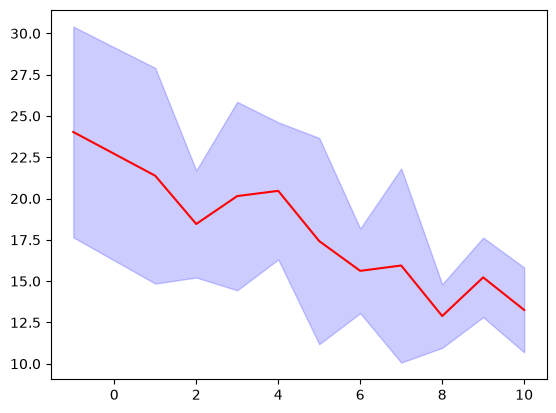

In [5]:
plt.figure()
plt.plot(best_df_all.iter, best_df_all.best_loss_mean,color="red")
plt.fill_between(best_df_all.iter, 
                 best_df_all.best_loss_mean - best_df_all.best_loss_std, 
                 best_df_all.best_loss_mean + best_df_all.best_loss_std, 
                 alpha=0.2, color = 'blue')

# TurBO

In [2]:
n_trust_regions=3
x_dim=98
num_restarts=5
niter=10
tr_candidates_generator=TRCandidatesGeneration(x_dim)
init_sample_size=5

output_dir="turbo_initial_output/"
dtype=torch.double
x_dim=98
lower_bounds=[5]*x_dim
additional_xml_gt="./Ingolstadt Network/additional_gt.xml"
initial_tl_df=create_initial_tl_df(additional_xml_gt)
upper_bounds=get_upper_bounds(initial_tl_df)
bounds=torch.tensor(
    [lower_bounds,
    upper_bounds],
    dtype=dtype
)


df_gt=pd.read_csv("./gt_data/gt_InTAS.travel_times.csv")
net=sumolib.net.readNet("Ingolstadt Network/ingolstadt.net.xml")
tl_ids=[tl.getID() for tl in net.getTrafficLights()]
num_replications=5
cfg_file="./Ingolstadt Network/InTAS.sumocfg"
additional_xml="./Ingolstadt Network/additional.xml"

batch_size=1
device=(torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu"))


sumo_simulator=SumoSimulation(num_replications=num_replications,
                                   cfg_file=cfg_file,
                                   output_dir=output_dir,
                                   tl_ids=tl_ids,
                                   )

objective_function=ErrorFunction(
    initial_tl_df=initial_tl_df,
    output_dir=output_dir,
    sumo_simulator=sumo_simulator,
    df_gt=df_gt,
    additional_xml=additional_xml,
    tl_ids=tl_ids
)

initial_sampler=InitialSamples(dtype=dtype,
                               objective_function=objective_function,
                               initial_tl_df=initial_tl_df)

turbo_initializer=TrustRegionInitialization(initial_sampler=initial_sampler)

./Ingolstadt Network/InTAS.sumocfg


In [ ]:
all_trust_region_initial_x_norm,all_trust_region_initial_y,all_trust_region_initial_df=turbo_initializer.initialize_trust_regions(
    sample_size=init_sample_size,
    n_trust_regions=n_trust_regions,
    x_bounds=bounds,
    x_dim=x_dim,
    num_restarts=num_restarts)

torch.save(all_trust_region_initial_x_norm,"./turbo_initial_samples/all_trust_region_initial_x_norm.pt")
torch.save(all_trust_region_initial_y,"./turbo_initial_samples/all_trust_region_initial_y.pt")
torch.save(all_trust_region_initial_df,"./turbo_initial_samples/all_trust_region_initial_df.pt")

In [2]:
n_trust_regions=3
x_dim=98
num_restarts=5
niter=10
tr_candidates_generator=TRCandidatesGeneration(x_dim)
init_sample_size=5

output_dir="turbo_output/"
dtype=torch.double
x_dim=98
lower_bounds=[5]*x_dim
additional_xml_gt="./Ingolstadt Network/additional_gt.xml"
initial_tl_df=create_initial_tl_df(additional_xml_gt)
upper_bounds=get_upper_bounds(initial_tl_df)
bounds=torch.tensor(
    [lower_bounds,
    upper_bounds],
    dtype=dtype
)


df_gt=pd.read_csv("./gt_data/gt_InTAS.travel_times.csv")
net=sumolib.net.readNet("Ingolstadt Network/ingolstadt.net.xml")
tl_ids=[tl.getID() for tl in net.getTrafficLights()]
num_replications=5
cfg_file="./Ingolstadt Network/InTAS.sumocfg"
additional_xml="./Ingolstadt Network/additional.xml"

batch_size=1
device=(torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu"))


sumo_simulator=SumoSimulation(num_replications=num_replications,
                                   cfg_file=cfg_file,
                                   output_dir=output_dir,
                                   tl_ids=tl_ids,
                                   )

objective_function=ErrorFunction(
    initial_tl_df=initial_tl_df,
    output_dir=output_dir,
    sumo_simulator=sumo_simulator,
    df_gt=df_gt,
    additional_xml=additional_xml,
    tl_ids=tl_ids
)


trust_region_initial_x_norm_list=torch.load("./turbo_initial_samples/all_trust_region_initial_x_norm.pt",weights_only=False)
trust_region_initial_y_list=torch.load("./turbo_initial_samples/all_trust_region_initial_y.pt",weights_only=False)
trust_region_initial_df_list=torch.load("./turbo_initial_samples/all_trust_region_initial_df.pt",weights_only=False)

torbo_bo_launcher=TurboLoop(
    n_trust_regions=n_trust_regions,
    dim=x_dim,
    num_restarts=num_restarts,
    tr_candidates_generator=tr_candidates_generator,
    objective_function=objective_function,
    trust_region_initial_x_norm_list=trust_region_initial_x_norm_list,
    trust_region_initial_y_list=trust_region_initial_y_list,
    trust_region_initial_df_list=trust_region_initial_df_list,
    batch_size=batch_size,
    niter=niter,
    bounds=bounds
)

In [3]:
torbo_bo_launcher.turbo_loop()

G VEC ALL :
[64  5 36 16 45 21 78  6  4 62 63 24 38 31 79  5 26 49 49 11 45 13 65  6
 14 70 41 25 27 57 46 38 32  4 26 58 71  3 40 44 19 17 27 57 61 19 55 20
 17 55 64 11 28 34 27 27 59 25 25 29 60 15 43 36 30 35 38 46 80  4 53 22
  8 67 26 58 48 27 18 57  3 32 10 26 10 65  8 46 36 39 47 28 65  7 67  5
 40 44 27 42  5 79  5 70  7 77 49 17 34 41 45 30 29 29 43 32 27 21 43 15
 14 50 49  5 16 32 54 33 20 20 47 28 39 36 55 20 10 44 26 18 47 11 22 44
 26 40 44  7 32 43 21 54 11 55 32 43 36 39 21 45 35 13 59  2 14  7 53 22
 35 24 21 51 66  9 50 16 37 38 38 10 23 52  6 78 28 41 11 47 70  5 30 39
 17 58  8 67]
Wrote ./Ingolstadt Network/additional.xml
Erreur SUMO/TraCI : Connection closed by SUMO.


Traceback (most recent call last):
  File "c:\Users\sh032\OneDrive - HEC Montréal\Documents\Master 1\Session 3\Sample Efficient Optimization\Bayesian-Optimization-for-Traffic-Signal-Green-Time-Calibration\modules\sumo_simulation.py", line 26, in simulation
    traci.start([
  File "C:\Program Files (x86)\Eclipse\Sumo\tools\traci\main.py", line 147, in start
    result = init(sumoPort, numRetries, "localhost", label, sumoProcess, doSwitch, traceFile, traceGetters)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files (x86)\Eclipse\Sumo\tools\traci\main.py", line 119, in init
    return con.getVersion()
           ^^^^^^^^^^^^^^^^
  File "C:\Program Files (x86)\Eclipse\Sumo\tools\traci\connection.py", line 383, in getVersion
    result = self._sendCmd(command, None, None)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files (x86)\Eclipse\Sumo\tools\traci\connection.py", line 232, in _sendCm

FileNotFoundError: [Errno 2] No such file or directory: './Ingolstadt Network/turbo_output/turbo_candidate_0_tr_0_iter_0_rs_0_0_InTAS.travel_times.xml'

In [9]:
upper_bounds

[68,
 51,
 65,
 83,
 65,
 86,
 68,
 83,
 74,
 59,
 57,
 70,
 83,
 65,
 83,
 83,
 35,
 83,
 73,
 83,
 35,
 83,
 79,
 74,
 71,
 74,
 61,
 53,
 83,
 53,
 74,
 78,
 64,
 83,
 83,
 74,
 74,
 83,
 74,
 74,
 34,
 35,
 74,
 53,
 74,
 74,
 71,
 71,
 83,
 68,
 83,
 74,
 83,
 65,
 74,
 74,
 57,
 74,
 47,
 57,
 63,
 53,
 47,
 86,
 39,
 74,
 74,
 74,
 53,
 43,
 57,
 65,
 65,
 50,
 74,
 74,
 65,
 74,
 74,
 65,
 47,
 60,
 20,
 74,
 58,
 71,
 74,
 65,
 74,
 47,
 74,
 83,
 68,
 57,
 74,
 68,
 74,
 74]